# Activity 2 – Binary Classification with Logistic Regression
**Course:** Regression and Classification Algorithms (T.Y. B.Tech AI & DS, CIE 2) | **GitHub:** [complexiota](https://github.com/complexiota)

## 1. Frame the problem
- **Role:** data scientist at a school/college support office.
- **User and decision:** teachers/counsellors decide which students get extra academic support early in the year.
- **Target (y):** `result` – **FAIL** if final grade `G3 < 10`, otherwise **PASS**.
- **Positive class = FAIL (student at risk)**, because the team acts on a positive prediction by offering support.
- **Features (X):** personal, family and school factors. `G1`, `G2`, `G3` (grades of the same course) are removed to prevent leakage, and `Dalc`, `Walc` (alcohol use) are also removed as sensitive.
- **Costly error:** a **false negative** (an at-risk student predicted PASS) is worse than a false positive (a student offered support who did not need it).
- **Success metric:** recall for FAIL, checked together with precision and ROC-AUC, and compared with the majority-class baseline.

## 2. Data source
UCI Machine Learning Repository – *Student Performance* dataset (P. Cortez and A. Silva, 2008), Mathematics course file `student-mat.csv`. One row = one student. Source: https://archive.ics.uci.edu/dataset/320/student+performance

The Portuguese file and the combined file are **not** used here: many students appear in both files, so a random split would put the same student in train and test (leakage).

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, roc_auc_score, roc_curve,
                             precision_recall_curve)
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("../visualizations", exist_ok=True)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Python 3.12.3 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 3. Inspect the data

In [2]:
df = pd.read_csv("../dataset/student-mat.csv", sep=None, engine="python")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
print(df.dtypes.value_counts())
print("\nMissing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df.describe().T.round(2)

str      17
int64    16
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0


In [4]:
# data dictionary (short): numeric = counts/ratings, object = categories
print("Categorical:", df.select_dtypes(exclude=np.number).columns.tolist())
print("Numeric:", df.select_dtypes(include=np.number).columns.tolist())
print("\nInconsistent labels check (unique values per categorical column):")
for c in df.select_dtypes(exclude=np.number).columns: print(f"  {c}: {sorted(df[c].unique())}")

Categorical: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Numeric: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Inconsistent labels check (unique values per categorical column):
  school: ['GP', 'MS']
  sex: ['F', 'M']
  address: ['R', 'U']
  famsize: ['GT3', 'LE3']
  Pstatus: ['A', 'T']
  Mjob: ['at_home', 'health', 'other', 'services', 'teacher']
  Fjob: ['at_home', 'health', 'other', 'services', 'teacher']
  reason: ['course', 'home', 'other', 'reputation']
  guardian: ['father', 'mother', 'other']
  schoolsup: ['no', 'yes']
  famsup: ['no', 'yes']
  paid: ['no', 'yes']
  activities: ['no', 'yes']
  nursery: ['no', 'yes']
  higher: ['no', 'yes']
  internet: ['no', 'yes']
  romantic: ['no', 'yes']


### Create the target and check class balance

result
PASS    265
FAIL    130
Name: count, dtype: int64 
 result
PASS    0.671
FAIL    0.329
Name: count, dtype: float64


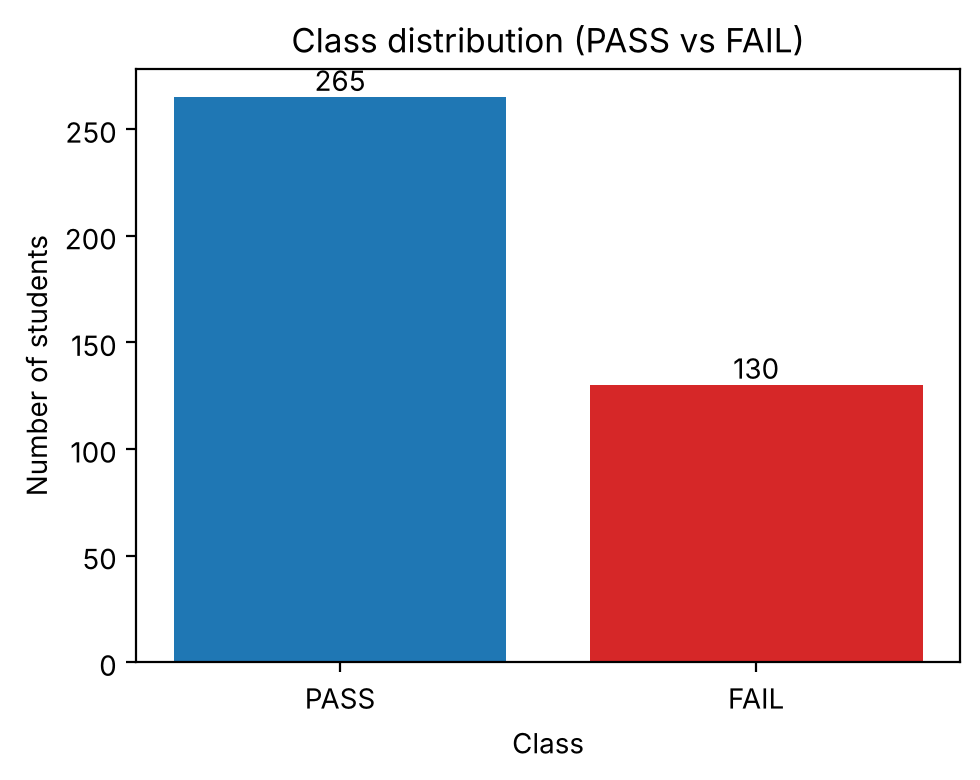

Observation: PASS is the majority class (67.1%). The classes are moderately imbalanced, so a model that always says PASS already gets 67.1% accuracy – accuracy alone cannot be trusted.


In [5]:
EXCLUDE = ["G1", "G2", "G3", "Dalc", "Walc"]
df["result"] = np.where(df["G3"] >= 10, "PASS", "FAIL")
counts = df["result"].value_counts()
print(counts, "\n", (counts / len(df)).round(3))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(counts.index, counts.values, color=["tab:blue", "tab:red"])
for i, v in enumerate(counts.values): ax.text(i, v + 3, str(v), ha="center")
ax.set_title("Class distribution (PASS vs FAIL)"); ax.set_xlabel("Class"); ax.set_ylabel("Number of students")
plt.tight_layout(); plt.savefig("../visualizations/class_distribution.png", dpi=120); plt.show()
major = counts.max() / len(df)
print(f"Observation: PASS is the majority class ({major:.1%}). The classes are moderately imbalanced, "
      f"so a model that always says PASS already gets {major:.1%} accuracy – accuracy alone cannot be trusted.")

## 4. Prepare features and split (stratified, scaler fitted on train only)

In [6]:
X = df.drop(columns=EXCLUDE + ["result"])
y = (df["result"] == "FAIL").astype(int)          # 1 = FAIL (positive class), 0 = PASS
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("FAIL share  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))
print("Class counts train:", y_train.value_counts().to_dict(), "| test:", y_test.value_counts().to_dict())

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))]), cat_cols),
])
model = Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=1000, solver="lbfgs", random_state=SEED))])

Train: (316, 28) | Test: (79, 28)
FAIL share  train: 0.329 | test: 0.329
Class counts train: {0: 212, 1: 104} | test: {0: 53, 1: 26}


**Why these choices:** there are no missing values, but the imputers make the pipeline safe for new data. Numeric features are standardised because the L-BFGS optimiser converges more reliably and coefficients become comparable. Categorical features are one-hot encoded (no natural order). Because everything sits inside one `Pipeline`, the scaler and encoder are fitted on the training data only. The split is stratified so FAIL keeps the same share in both sets.

## 5. Why not linear regression? The sigmoid
Linear regression predicts any real number (it can output -3 or 1.7), which is meaningless as a probability, and its squared-error fit is distorted by a 0/1 target. Logistic regression passes a linear score `z` through the **sigmoid** `σ(z) = 1 / (1 + e^(−z))`, which squeezes it into (0, 1). That value is read as P(FAIL), and a **decision threshold** (default 0.5) converts it into a label.

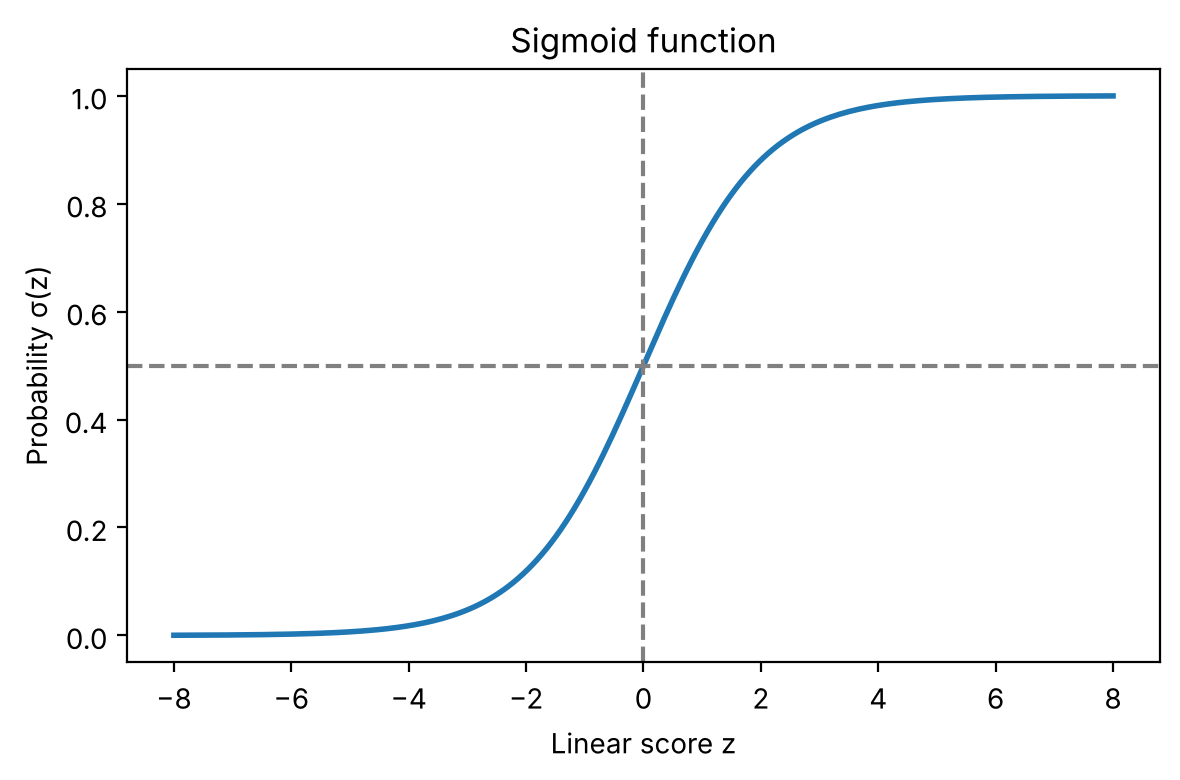

In [7]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 4)); plt.plot(z, 1 / (1 + np.exp(-z)), lw=2)
plt.axhline(0.5, ls="--", c="grey"); plt.axvline(0, ls="--", c="grey")
plt.title("Sigmoid function"); plt.xlabel("Linear score z"); plt.ylabel("Probability σ(z)")
plt.tight_layout(); plt.savefig("../visualizations/sigmoid.png", dpi=120); plt.show()

## 6. Baseline and model training

In [8]:
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
b_pred = base.predict(X_test)
print("Baseline (always predict the majority class = PASS):")
print("  accuracy = %.3f | recall(FAIL) = %.3f | precision(FAIL) = %.3f"
      % (accuracy_score(y_test, b_pred), recall_score(y_test, b_pred), precision_score(y_test, b_pred, zero_division=0)))

model.fit(X_train, y_train)
print("\nSettings:", model.named_steps["lr"].get_params())

Baseline (always predict the majority class = PASS):


  accuracy = 0.671 | recall(FAIL) = 0.000 | precision(FAIL) = 0.000

Settings: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


### Coefficients and intercept

In [9]:
names = model.named_steps["pre"].get_feature_names_out()
coef = pd.DataFrame({"feature": names, "coefficient": model.named_steps["lr"].coef_[0]})
coef["odds_ratio"] = np.exp(coef["coefficient"])
coef = coef.reindex(coef["coefficient"].abs().sort_values(ascending=False).index).reset_index(drop=True)
print("Intercept:", round(model.named_steps["lr"].intercept_[0], 4))
coef.head(12).round(3)

Intercept: -1.3099


,feature,coefficient,odds_ratio
0,cat__schoolsup_yes,0.669,1.953
1,num__failures,0.610,1.840
2,cat__Pstatus_T,0.523,1.687
3,cat__famsup_yes,0.511,1.666
4,cat__higher_yes,-0.482,0.617
5,cat__reason_course,0.471,1.601
6,cat__Mjob_teacher,0.469,1.598
7,cat__Mjob_services,-0.435,0.647
8,num__goout,0.409,1.506
9,cat__nursery_yes,0.395,1.484


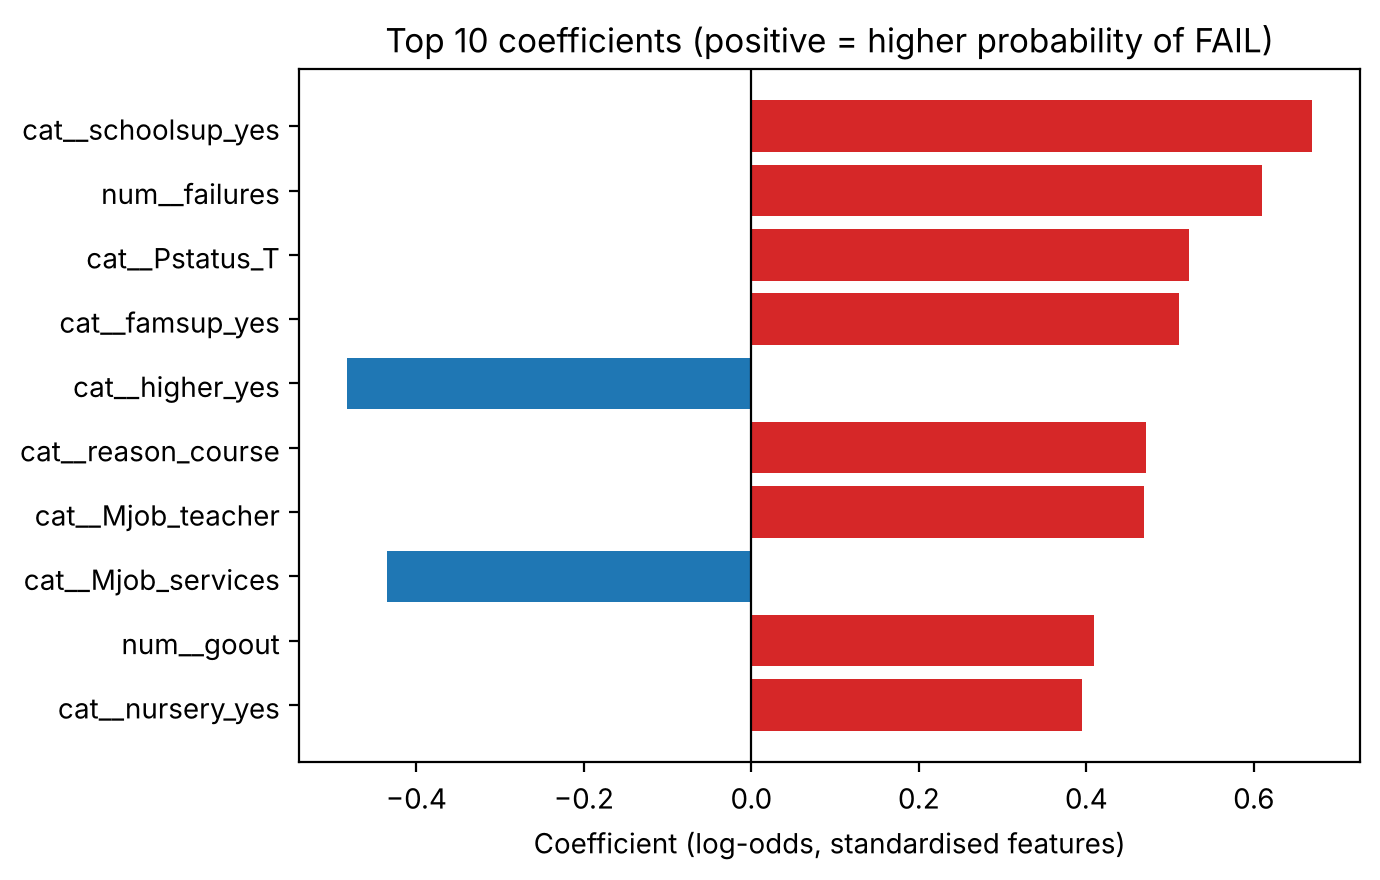

Interpretation: a POSITIVE coefficient raises the log-odds (probability) of FAIL; a NEGATIVE one lowers it.
Strongest risk factor: cat__schoolsup_yes (odds x1.95 per 1 std / vs reference); strongest protective factor: cat__higher_yes (odds x0.62). These show association, not causation.


In [10]:
top = coef.head(10).iloc[::-1]
plt.figure(figsize=(7, 4.5))
plt.barh(top["feature"], top["coefficient"], color=np.where(top["coefficient"] > 0, "tab:red", "tab:blue"))
plt.axvline(0, c="k", lw=0.8); plt.title("Top 10 coefficients (positive = higher probability of FAIL)")
plt.xlabel("Coefficient (log-odds, standardised features)"); plt.tight_layout()
plt.savefig("../visualizations/coefficients.png", dpi=120); plt.show()
up, dn = coef[coef.coefficient > 0].iloc[0], coef[coef.coefficient < 0].iloc[0]
print(f"Interpretation: a POSITIVE coefficient raises the log-odds (probability) of FAIL; a NEGATIVE one lowers it.\n"
      f"Strongest risk factor: {up.feature} (odds x{up.odds_ratio:.2f} per 1 std / vs reference); "
      f"strongest protective factor: {dn.feature} (odds x{dn.odds_ratio:.2f}). These show association, not causation.")

## 7. Predicted probabilities, labels and the effect of the threshold

In [11]:
proba = model.predict_proba(X_test)[:, 1]      # P(FAIL)
pred = (proba >= 0.5).astype(int)
sample = pd.DataFrame({"actual": np.where(y_test == 1, "FAIL", "PASS"),
                       "P(FAIL)": proba.round(3),
                       "predicted": np.where(pred == 1, "FAIL", "PASS")}, index=y_test.index).head(10)
display(sample)
for t in (0.3, 0.5, 0.7):
    print(f"threshold {t}: {(proba >= t).sum()} of {len(proba)} test students predicted FAIL")

,actual,P(FAIL),predicted
383,FAIL,0.521,FAIL
19,PASS,0.117,PASS
193,PASS,0.203,PASS
343,FAIL,0.168,PASS
92,FAIL,0.362,PASS
223,PASS,0.301,PASS
376,PASS,0.700,FAIL
265,PASS,0.306,PASS
297,FAIL,0.440,PASS
138,PASS,0.362,PASS


threshold 0.3: 37 of 79 test students predicted FAIL
threshold 0.5: 15 of 79 test students predicted FAIL
threshold 0.7: 6 of 79 test students predicted FAIL


## 8. Evaluation on the test set (threshold 0.5)

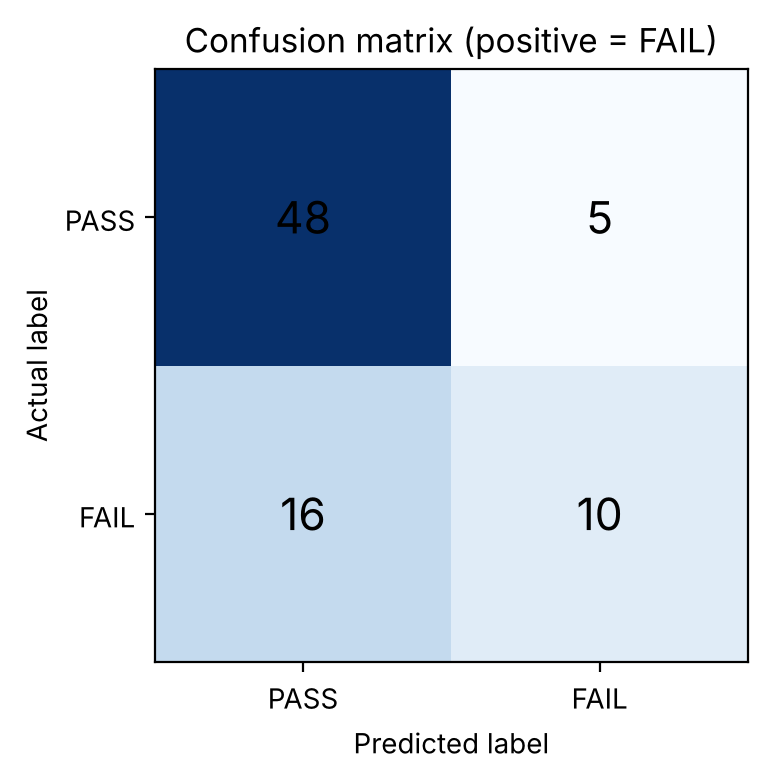

TP=10: at-risk students correctly flagged     | FP=5: students flagged who would have passed (wasted support)
FN=16: at-risk students MISSED (costliest)     | TN=48: passing students correctly cleared


In [12]:
cm = confusion_matrix(y_test, pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha="center", va="center", fontsize=16)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["PASS", "FAIL"]); ax.set_yticklabels(["PASS", "FAIL"])
ax.set_xlabel("Predicted label"); ax.set_ylabel("Actual label"); ax.set_title("Confusion matrix (positive = FAIL)")
plt.tight_layout(); plt.savefig("../visualizations/confusion_matrix.png", dpi=120); plt.show()
print(f"TP={tp}: at-risk students correctly flagged     | FP={fp}: students flagged who would have passed (wasted support)")
print(f"FN={fn}: at-risk students MISSED (costliest)     | TN={tn}: passing students correctly cleared")

In [13]:
acc  = (tp + tn) / (tp + tn + fp + fn)
prec = tp / (tp + fp) if (tp + fp) else 0.0
rec  = tp / (tp + fn)
spec = tn / (tn + fp)
f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
auc  = roc_auc_score(y_test, proba)
res = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall (sensitivity)", "Specificity", "F1-score", "ROC-AUC"],
    "Formula": ["(TP+TN)/(TP+TN+FP+FN)", "TP/(TP+FP)", "TP/(TP+FN)", "TN/(TN+FP)", "2PR/(P+R)", "area under ROC curve"],
    "Test value": [acc, prec, rec, spec, f1, auc],
    "Meaning": ["share of all predictions that are correct",
                "of students flagged FAIL, how many truly fail",
                "of students who truly fail, how many we caught",
                "of students who truly pass, how many we cleared",
                "balance of precision and recall",
                "ability to rank failing students above passing ones (0.5 = chance)"]})
res["Test value"] = res["Test value"].round(3)
display(res)
print(f"Interpretation: at threshold 0.5 the model catches {rec:.0%} of at-risk students (recall) and "
      f"{prec:.0%} of its FAIL flags are correct; ROC-AUC = {auc:.2f}.")

,Metric,Formula,Test value,Meaning
0,Accuracy,(TP+TN)/(TP+TN+FP+FN),0.734,share of all predictions that are correct
1,Precision,TP/(TP+FP),0.667,"of students flagged FAIL, how many truly fail"
2,Recall (sensitivity),TP/(TP+FN),0.385,"of students who truly fail, how many we caught"
3,Specificity,TN/(TN+FP),0.906,"of students who truly pass, how many we cleared"
4,F1-score,2PR/(P+R),0.488,balance of precision and recall
5,ROC-AUC,area under ROC curve,0.713,ability to rank failing students above passing...


Interpretation: at threshold 0.5 the model catches 38% of at-risk students (recall) and 67% of its FAIL flags are correct; ROC-AUC = 0.71.


In [14]:
print(classification_report(y_test, pred, target_names=["PASS", "FAIL"], digits=3))

              precision    recall  f1-score   support

        PASS      0.750     0.906     0.821        53
        FAIL      0.667     0.385     0.488        26

    accuracy                          0.734        79
   macro avg      0.708     0.645     0.654        79
weighted avg      0.723     0.734     0.711        79



### Comparison with the majority-class baseline

In [15]:
cmp = pd.DataFrame({
    "model": ["Baseline (always PASS)", "Logistic Regression (0.5)"],
    "accuracy": [accuracy_score(y_test, b_pred), acc],
    "recall (FAIL)": [recall_score(y_test, b_pred), rec],
    "precision (FAIL)": [precision_score(y_test, b_pred, zero_division=0), prec]}).round(3)
display(cmp)
print("Observation: accuracy of the baseline is", round(accuracy_score(y_test, b_pred), 3),
      "- accuracy alone would make the model look no better (or worse) than doing nothing, "
      "but the baseline catches 0% of at-risk students, while the model catches", f"{rec:.0%}.",
      "That is why recall for FAIL, not accuracy, is the metric that matters here.")

,model,accuracy,recall (FAIL),precision (FAIL)
0,Baseline (always PASS),0.671,0.000,0.000
1,Logistic Regression (0.5),0.734,0.385,0.667


Observation: accuracy of the baseline is 0.671 - accuracy alone would make the model look no better (or worse) than doing nothing, but the baseline catches 0% of at-risk students, while the model catches 38%. That is why recall for FAIL, not accuracy, is the metric that matters here.


### ROC curve (and precision–recall curve, because classes are imbalanced)

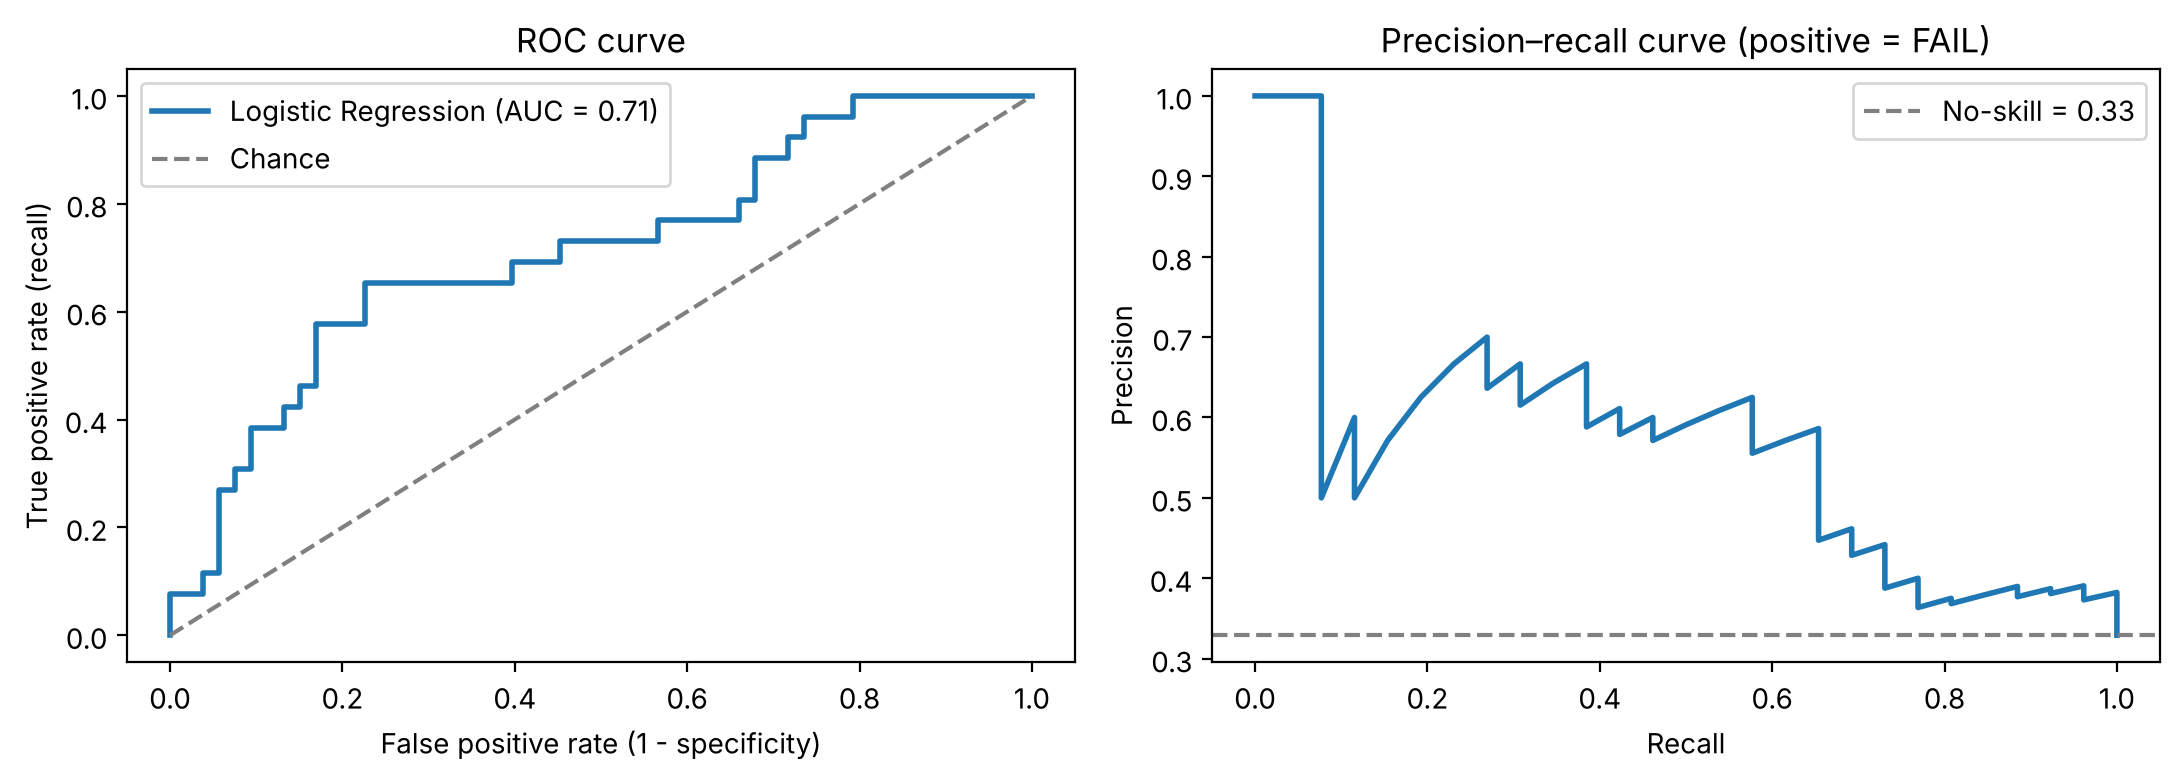

ROC-AUC = 0.713: if we pick one failing and one passing student at random, the model gives the failing student the higher P(FAIL) about 71% of the time (50% would be pure chance).


In [16]:
fpr, tpr, _ = roc_curve(y_test, proba)
p_, r_, _ = precision_recall_curve(y_test, proba)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr, lw=2, label=f"Logistic Regression (AUC = {auc:.2f})"); ax[0].plot([0, 1], [0, 1], "--", c="grey", label="Chance")
ax[0].set_xlabel("False positive rate (1 - specificity)"); ax[0].set_ylabel("True positive rate (recall)"); ax[0].set_title("ROC curve"); ax[0].legend()
ax[1].plot(r_, p_, lw=2); ax[1].axhline(y_test.mean(), ls="--", c="grey", label=f"No-skill = {y_test.mean():.2f}")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision–recall curve (positive = FAIL)"); ax[1].legend()
plt.tight_layout(); plt.savefig("../visualizations/roc_pr_curves.png", dpi=120); plt.show()
print(f"ROC-AUC = {auc:.3f}: if we pick one failing and one passing student at random, the model gives the failing "
      f"student the higher P(FAIL) about {auc:.0%} of the time (50% would be pure chance).")

### Threshold comparison

In [17]:
rows = []
for t in (0.3, 0.5, 0.7):
    p = (proba >= t).astype(int)
    rows.append({"Threshold": t, "Predicted FAIL": int(p.sum()), "Accuracy": accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p, zero_division=0), "Recall": recall_score(y_test, p),
                 "F1-score": f1_score(y_test, p, zero_division=0)})
thr = pd.DataFrame(rows).round(3); display(thr)

,Threshold,Predicted FAIL,Accuracy,Precision,Recall,F1-score
0,0.3,37,0.633,0.459,0.654,0.540
1,0.5,15,0.734,0.667,0.385,0.488
2,0.7,6,0.671,0.500,0.115,0.188


**Trade-off:** lowering the threshold flags more students, so recall rises (fewer missed at-risk students) but precision falls (more unnecessary flags). Raising it does the opposite. Because a missed at-risk student (FN) is costlier than offering extra support to a student who did not need it (FP), a **lower threshold (about 0.3)** is recommended – see the decision log below.

### Training vs test (over/underfitting check)

In [18]:
tr_p = model.predict_proba(X_train)[:, 1]
tt = pd.DataFrame({"set": ["train", "test"],
    "accuracy": [accuracy_score(y_train, tr_p >= .5), acc],
    "recall": [recall_score(y_train, tr_p >= .5), rec],
    "ROC-AUC": [roc_auc_score(y_train, tr_p), auc]}).round(3)
display(tt)
gap = tt.loc[0, "ROC-AUC"] - tt.loc[1, "ROC-AUC"]
print(f"Train–test ROC-AUC gap = {gap:.2f}.",
      "A large gap indicates overfitting (the model memorised noise in a small training set of 316 rows)." if gap > 0.1
      else "The gap is small, so overfitting is not the main issue.",
      "Low scores on BOTH sets would indicate underfitting / weak signal.")

,set,accuracy,recall,ROC-AUC
0,train,0.756,0.433,0.792
1,test,0.734,0.385,0.713


Train–test ROC-AUC gap = 0.08. The gap is small, so overfitting is not the main issue. Low scores on BOTH sets would indicate underfitting / weak signal.


### How stable is this result? (5-fold stratified cross-validation on the training set)

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
print("CV ROC-AUC per fold:", cv_auc.round(3), "| mean = %.3f (+/- %.3f)" % (cv_auc.mean(), cv_auc.std()))
print("Interpretation: the test set has only 79 students, so a single split is noisy. The cross-validated mean is the more "
      "reliable estimate of how well the model ranks at-risk students: modest, only somewhat better than chance (0.5), so the model is a weak screening aid, not a reliable predictor.")

CV ROC-AUC per fold: [0.587 0.684 0.621 0.713 0.558] | mean = 0.633 (+/- 0.058)
Interpretation: the test set has only 79 students, so a single split is noisy. The cross-validated mean is the more reliable estimate of how well the model ranks at-risk students: modest, only somewhat better than chance (0.5), so the model is a weak screening aid, not a reliable predictor.


## 9. Decision behaviour: probability vs a feature

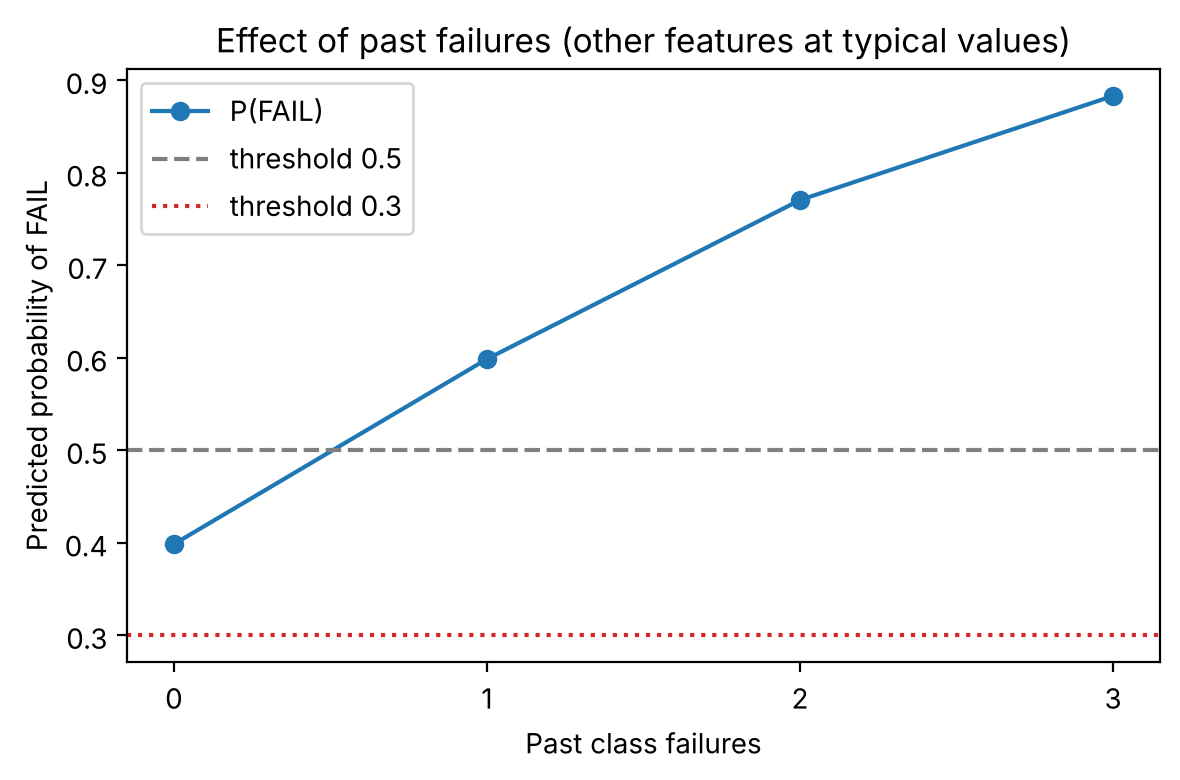

Observation: P(FAIL) rises smoothly (S-shaped) as past failures increase, crossing the thresholds at: 0 failure(s) -> 0.40, 1 failure(s) -> 0.60, 2 failure(s) -> 0.77, 3 failure(s) -> 0.88.


In [20]:
feat = "failures"   # number of past class failures – most intuitive driver of risk
grid = pd.DataFrame([X_train.median(numeric_only=True)] * 4)
for c in cat_cols: grid[c] = X_train[c].mode()[0]
grid = grid[X.columns]; grid[feat] = [0, 1, 2, 3]
pg = model.predict_proba(grid)[:, 1]
plt.figure(figsize=(6, 4)); plt.plot(grid[feat], pg, "o-", label="P(FAIL)")
plt.axhline(0.5, ls="--", c="grey", label="threshold 0.5"); plt.axhline(0.3, ls=":", c="tab:red", label="threshold 0.3")
plt.xticks([0, 1, 2, 3]); plt.xlabel("Past class failures"); plt.ylabel("Predicted probability of FAIL")
plt.title("Effect of past failures (other features at typical values)"); plt.legend(); plt.tight_layout()
plt.savefig("../visualizations/probability_vs_failures.png", dpi=120); plt.show()
print("Observation: P(FAIL) rises smoothly (S-shaped) as past failures increase, crossing the thresholds at: "
      + ", ".join(f"{int(f)} failure(s) -> {p:.2f}" for f, p in zip(grid[feat], pg)) + ".")

## 10. Classify a new student

In [21]:
new = X_train.median(numeric_only=True).to_dict()
for c in cat_cols: new[c] = X_train[c].mode()[0]
new.update({"age": 17, "studytime": 2, "failures": 1, "absences": 6, "higher": "yes", "schoolsup": "no"})
new_df = pd.DataFrame([new])[X.columns]
p_new = model.predict_proba(new_df)[0, 1]
print(f"New student -> P(FAIL) = {p_new:.2f}; at 0.5: {'FAIL' if p_new>=.5 else 'PASS'} | at recommended 0.3: {'FAIL' if p_new>=.3 else 'PASS'}")
print("This is a probability-based estimate, not a guaranteed outcome.")

New student -> P(FAIL) = 0.61; at 0.5: FAIL | at recommended 0.3: FAIL
This is a probability-based estimate, not a guaranteed outcome.


## 11. Decision log
| Decision | Alternatives considered | Reason |
|---|---|---|
| Positive class = FAIL | Positive = PASS | Support staff act on at-risk students, so metrics (recall, precision) should describe that group |
| Drop G1, G2, G3 | Keep G1/G2 | G1/G2 are earlier grades of the same course and make prediction almost trivial (leakage); the goal is an early warning |
| Drop Dalc, Walc | Keep | Sensitive personal behaviour; also not needed for the decision |
| Use only the Math file | Combined Math + Portuguese | Same students appear in both files, which would leak between train and test |
| Stratified 80:20 split, seed 42 | Plain random split | Keeps FAIL share equal in both sets; reproducible |
| Main metric = recall (FAIL), then precision and ROC-AUC | Accuracy | The majority-class baseline already gets high accuracy and catches no at-risk student |
| Recommended threshold ≈ 0.3 | 0.5 default | A missed at-risk student costs more than unnecessary support; accepts lower precision |

## 12. Conclusion and limitations
- A logistic regression model with leakage-free features ranks at-risk students only modestly (test ROC-AUC 0.71 on this split, but the cross-validated mean is about 0.63, so expect roughly 0.6–0.7). At the default 0.5 threshold it is only a few accuracy points better than the always-PASS baseline and misses most at-risk students (recall about 0.38), but unlike the baseline it finds some of them. Lowering the threshold to about 0.3 raises recall substantially at the cost of precision (see the threshold table).
- **Limitations:** only 395 students from two Portuguese schools; weak signal without earlier grades; coefficients show association, not causation; results vary with the random split (the test set has only 79 rows).
- **Ethics / do-not-use:** the model must **not** be used to deny any student an opportunity or to make decisions on its own – only to prioritise who gets a supportive conversation. Wrong predictions could label a student unfairly or miss one who needs help.